In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

In [9]:
INPUT_DIR = "/content/drive/MyDrive/Group_AIML/Member 02_IT25103229/Outputs"
OUTPUT_DIR = "/content/drive/MyDrive/Group_AIML/Member 06_IT25103274/Outputs"
EDA_DIR = "/content/drive/MyDrive/Group_AIML/Member 06_IT25103274/EDA"
LOCAL_SAVE_DIR = "/content/local_outputs"

In [10]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(EDA_DIR, exist_ok=True)
os.makedirs(LOCAL_SAVE_DIR, exist_ok=True)

print("Exists:", os.path.exists(INPUT_DIR))
print("Contents of INPUT_DIR:", os.listdir(INPUT_DIR))

Exists: True
Contents of INPUT_DIR: ['validation_normalized_images.npy', 'train_normalized_images.npy', 'train_labels.npy', 'train_filepaths.npy', 'validation_labels.npy', 'validation_filepaths.npy']


In [11]:
# Combined channel-count bins (shared across both splits)
# Channels seen: 1 (grayscale), 2 (grayscale+alpha), 3 (RGB), 4 (RGBA/CMYK)
combined_channel_hist_before = {1: 0, 2: 0, 3: 0, 4: 0}
combined_channel_hist_after = {1: 0, 2: 0, 3: 0, 4: 0}

In [12]:
# Process Train and Validation, one image at a time
for split in ["train", "validation"]:   # matches Member 2's saved file naming
    array_path = os.path.join(INPUT_DIR, f"{split}_normalized_images.npy")
    labels_path = os.path.join(INPUT_DIR, f"{split}_labels.npy")

    if not os.path.exists(array_path):
        print(f"WARNING: {array_path} does not exist -- check folder name/path")
        continue

    images = np.load(array_path, mmap_mode="r")
    labels = np.load(labels_path, allow_pickle=True)

    N = images.shape[0]
    print(f"\n{split}: found {N} images, array shape {images.shape}")

    # On-disk output array -- writes each image directly to disk, RAM stays small
    memmap_path = os.path.join(LOCAL_SAVE_DIR, f"{split}_channel_checked_images.npy")
    output_array = np.lib.format.open_memmap(
        memmap_path, mode="w+", dtype="float32", shape=(N, 224, 224, 3)
    )

    channel_records = []

    for i in tqdm(range(N), desc=f"Checking channels {split}"):
        img = images[i]

        # Determine original channel count for this image
        if img.ndim == 2:
            n_channels = 1
        elif img.ndim == 3:
            n_channels = img.shape[-1]
        else:
            n_channels = -1

        combined_channel_hist_before[n_channels] = combined_channel_hist_before.get(n_channels, 0) + 1

        # Convert to consistent RGB (3 channels) if needed
        if n_channels == 1:
            fixed = np.repeat(img[..., np.newaxis] if img.ndim == 2 else img, 3, axis=-1)
        elif n_channels == 4:
            fixed = img[..., :3]
        elif n_channels == 3:
            fixed = img
        else:
            fixed = np.zeros((224, 224, 3), dtype="float32")  # fallback, flagged below

        output_array[i] = fixed
        combined_channel_hist_after[3] = combined_channel_hist_after.get(3, 0) + 1

        channel_records.append({
            "split": split,
            "index": i,
            "class": labels[i],
            "original_channels": n_channels,
            "final_channels": 3,
            "was_fixed": n_channels != 3
        })

    output_array.flush()
    print(f"{split}: saved channel-checked array locally to {memmap_path}")

    # Save per-image manifest for this split
    manifest_df = pd.DataFrame(channel_records)
    manifest_local_path = os.path.join(LOCAL_SAVE_DIR, f"{split}_channel_manifest.csv")
    manifest_df.to_csv(manifest_local_path, index=False)

    # ---- Copy all this split's files to Drive ----
    for fname in [f"{split}_channel_checked_images.npy", f"{split}_channel_manifest.csv"]:
        print(f"Copying {fname} to Drive...")
        shutil.copy(os.path.join(LOCAL_SAVE_DIR, fname), os.path.join(OUTPUT_DIR, fname))
        print(f"Done: {fname}")

    print(f"Saved {split} outputs to {OUTPUT_DIR}")

    # Release the memmap reference for this split before moving to the next
    del output_array


train: found 11662 images, array shape (11662, 224, 224, 3)


Checking channels train: 100%|██████████| 11662/11662 [02:36<00:00, 74.65it/s]


train: saved channel-checked array locally to /content/local_outputs/train_channel_checked_images.npy
Copying train_channel_checked_images.npy to Drive...
Done: train_channel_checked_images.npy
Copying train_channel_manifest.csv to Drive...
Done: train_channel_manifest.csv
Saved train outputs to /content/drive/MyDrive/Group_AIML/Member 06_IT25103274/Outputs

validation: found 2012 images, array shape (2012, 224, 224, 3)


Checking channels validation: 100%|██████████| 2012/2012 [00:18<00:00, 110.24it/s]


validation: saved channel-checked array locally to /content/local_outputs/validation_channel_checked_images.npy
Copying validation_channel_checked_images.npy to Drive...
Done: validation_channel_checked_images.npy
Copying validation_channel_manifest.csv to Drive...
Done: validation_channel_manifest.csv
Saved validation outputs to /content/drive/MyDrive/Group_AIML/Member 06_IT25103274/Outputs


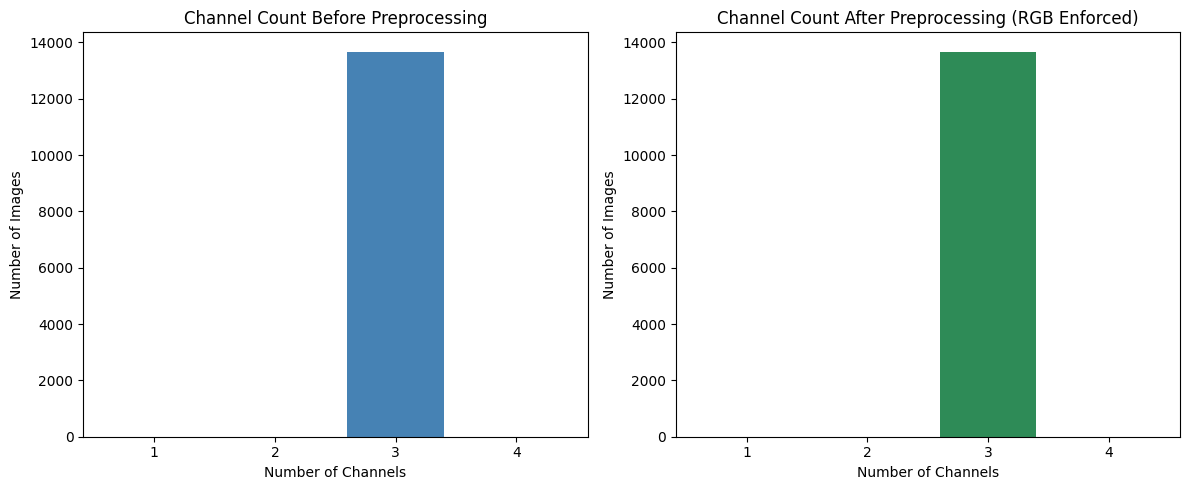


All done. Train and Validation channel-checked arrays saved to Outputs, chart saved to EDA.


In [13]:
# EDA: plot channel-count distribution before vs after (built incrementally, no big arrays needed)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

before_keys = sorted(combined_channel_hist_before.keys())
before_vals = [combined_channel_hist_before[k] for k in before_keys]

after_keys = sorted(combined_channel_hist_after.keys())
after_vals = [combined_channel_hist_after[k] for k in after_keys]

axes[0].bar([str(k) for k in before_keys], before_vals, color="steelblue")
axes[0].set_title("Channel Count Before Preprocessing")
axes[0].set_xlabel("Number of Channels")
axes[0].set_ylabel("Number of Images")

axes[1].bar([str(k) for k in after_keys], after_vals, color="seagreen")
axes[1].set_title("Channel Count After Preprocessing (RGB Enforced)")
axes[1].set_xlabel("Number of Channels")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "channel_distribution_before_after.png"))
plt.show()

print("\nAll done. Train and Validation channel-checked arrays saved to Outputs, chart saved to EDA.")